1.2 Activity: Week 1 Jupyter Notebook – Linear Regression 1

Week 1 Jupyter Notebook – Linear Regression 1
Each week, you will apply the concepts of that week to your Integrated Capstone Project’s dataset. In preparation for Milestone One, create a Jupyter Notebook (similar to in Module B, semester two) that illustrates these lessons. There are no specific questions to answer in your Jupyter Notebook files in this course; your general goal is to analyze your data, using the methods you have learned about in this course and in this program, and draw interesting conclusions. 

For Week 1, include concepts such as linear regression with polynomial terms, interaction terms, multicollinearity, variance inflation factor and regression, and categorical and continuous features. Complete your Jupyter Notebook homework by 11:59 pm ET on Sunday. 

In Week 7, you will compile your findings from your Jupyter Notebook homework into your Milestone One assignment for grading. For full instructions and the rubric for Milestone One, refer to the following link. 

LF recommendation:The notebooks are very open ended. You should form your own central question or central problem for the semester that you are using your datasets to answer.
Yes that is correct. I would use these notebooks as exploration for the new concepts and synthesize what you learned/your conclusions in the actual milestone 1 paper. For the Jupyter notebook itself there is no specific grading scheme we're more so looking for your engagement with the material in your datasets.

SUPPORT2 Dataset (Critical Care Patient Outcomes)   

Dataset Focus: 9,105 critically ill hospitalized patients with physiological, demographic, and disease-severity variables

Working Central Research Question: How does a patient's age, number of comorbidities, and disease category interact to predict length of stay or hospital outcomes, and how can multicollinearity among physiological indicators be controlled?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import seaborn as sns

In [2]:
#load SUPPORT2 dataset
df = pd.read_csv('support2.csv')

#clean and filter dataset to include relevant columns and drop rows with missing values
cols_to_use = ['age', 'num.co', 'dzclass', 'slos']
df_subset = df[cols_to_use].dropna()

#categorical features encoding using one-hot encoding for 'dzclass' while dropping first category to avoid multicollinearity
df_encoded = pd.get_dummies(
    df_subset, columns=['dzclass'], drop_first=True, dtype=int
)

#polynomial and interaction terms creation
df_encoded['age_squared'] = df_encoded['age'] ** 2

#interaction term:does comorbidity count affect age's impact on stay length?
df_encoded['age_x_num_co'] = df_encoded['age'] * df_encoded['num.co']

#define X(features) and y(target)
X = df_encoded.drop(columns=['slos'])
y = df_encoded['slos']

#add constant for statsmodels
X_vif = sm.add_constant(X)

#multicollinearity check using Variance Inflation Factor (VIF)
vif_data = pd.DataFrame()
vif_data['Feature'] = X_vif.columns
vif_data['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print('SUPPORT2 VIF REPORT')
 #High VIF expected due to raw polynomial terms (age & age_squared)
print(vif_data) 

#fit the regression model using Ordinary Least Squares (OLS)
model = sm.OLS(y, X_vif).fit()
print('\nSUPPORT2 REGRESSION SUMMARY')
print(model.summary())

SUPPORT2 VIF REPORT
                      Feature        VIF
0                       const   1.000000
1                         age  38.722067
2                      num.co  19.073865
3  dzclass_COPD/CHF/Cirrhosis   1.384923
4              dzclass_Cancer   1.174075
5                dzclass_Coma   1.077615
6                 age_squared  40.382467
7                age_x_num_co  21.848399

SUPPORT2 REGRESSION SUMMARY
                            OLS Regression Results                            
Dep. Variable:                   slos   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.091
Method:                 Least Squares   F-statistic:                     131.9
Date:                Sun, 18 Oct 2026   Prob (F-statistic):          1.05e-185
Time:                        17:35:49   Log-Likelihood:                -40625.
No. Observations:                9105   AIC:                         8.127e+04
Df Residuals:                

Diabetes 130-US Hospitals Dataset (Hospital Readmissions)   

Dataset Focus: 101,766 hospital encounters for diabetic patients across 130 US hospitals

Working Central Research Question: "How does time in a hospital, number of medications, and their interaction influence overall laboratory procedures, and how do we manage multicollinearity among clinical intensity metrics?"

In [3]:
#load DIABETES dataset
df = pd.read_csv('diabetic_data.csv')

#clean and filter dataset to include only relevant columns and drop rows with missing values
cols_to_use = [
    'time_in_hospital',
    'num_medications',
    'num_lab_procedures',
    'gender',
]
df_subset = df[cols_to_use].dropna()

#convert numeric columns to numeric types and handle errors by coercing invalid parsing to NaN, then drop rows with NaN values
df_subset['num_lab_procedures'] = pd.to_numeric(
    df_subset['num_lab_procedures'], errors='coerce'
)
df_subset['time_in_hospital'] = pd.to_numeric(
    df_subset['time_in_hospital'], errors='coerce'
)
df_subset['num_medications'] = pd.to_numeric(
    df_subset['num_medications'], errors='coerce'
)
df_subset = df_subset.dropna()

#categorical features encoding using one-hot encoding for 'gender' while dropping first category to avoid multicollinearity
df_encoded = pd.get_dummies(
    df_subset, columns=['gender'], drop_first=True, dtype=int
)
#polynomial and interaction terms creation
df_encoded['time_in_hospital_sq'] = df_encoded['time_in_hospital'] ** 2

#interaction term:time in hospital interacting with number of medications
df_encoded['time_x_meds'] = (
    df_encoded['time_in_hospital'] * df_encoded['num_medications']
)
#define X and y
X = df_encoded.drop(columns=['num_lab_procedures'])
y = df_encoded['num_lab_procedures']

#add constant for statsmodels
X_vif = sm.add_constant(X)

#multicollinearity check using Variance Inflation Factor (VIF)
vif_data = pd.DataFrame()
vif_data['Feature'] = X_vif.columns
vif_data['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print('DIABETES VIF REPORT')
print(vif_data)

#fit regression model using Ordinary Least Squares (OLS)
model = sm.OLS(y, X_vif).fit()
print('\nDIABETES REGRESSION SUMMARY')
print(model.summary())

DIABETES VIF REPORT
                  Feature        VIF
0                   const   1.000000
1        time_in_hospital  12.521102
2         num_medications   4.914701
3             gender_Male   1.002251
4  gender_Unknown/Invalid   1.000046
5     time_in_hospital_sq  14.904803
6             time_x_meds  13.275657

DIABETES REGRESSION SUMMARY
                            OLS Regression Results                            
Dep. Variable:     num_lab_procedures   R-squared:                       0.133
Model:                            OLS   Adj. R-squared:                  0.133
Method:                 Least Squares   F-statistic:                     2593.
Date:                Sun, 18 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:35:49   Log-Likelihood:            -4.4035e+05
No. Observations:              101766   AIC:                         8.807e+05
Df Residuals:                  101759   BIC:                         8.808e+05
Df Model:              

Visualization: Exploratory Data Analysis & Distribution of Hospital Length of Stay and Patient Charges across SUPPORT2 and Diabetes cohorts

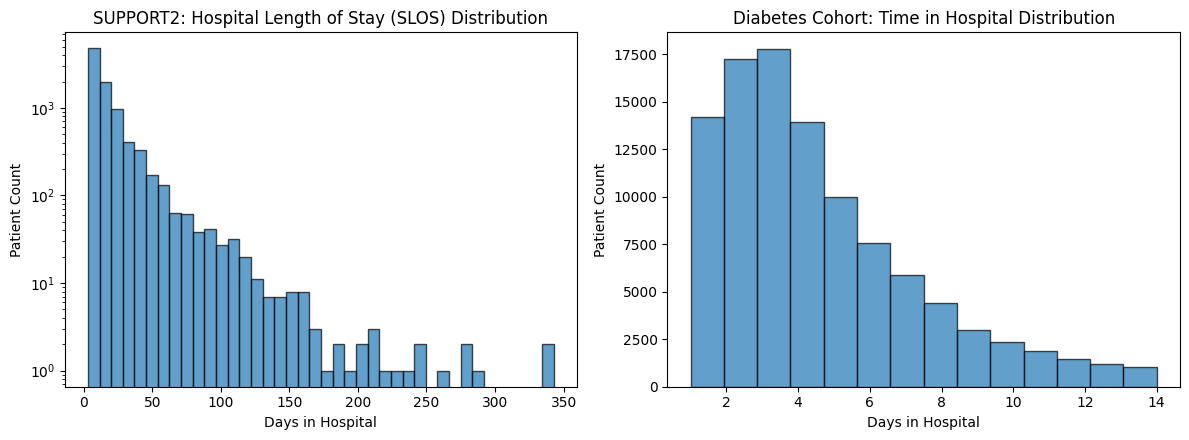

In [4]:
#load datasets
df_s = pd.read_csv('support2.csv')
df_d = pd.read_csv('diabetic_data.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
#SUPPORT2 SLOS distribution
axes[0].hist(df_s['slos'].dropna(), bins=40, edgecolor='black', alpha=0.7)
axes[0].set_title('SUPPORT2: Hospital Length of Stay (SLOS) Distribution')
axes[0].set_xlabel('Days in Hospital')
axes[0].set_ylabel('Patient Count')
#log scale to handle severe right-skewness
axes[0].set_yscale('log')
#diabetes in hospital stay distribution
axes[1].hist(
pd.to_numeric(df_d['time_in_hospital'], errors='coerce').dropna(),
bins=14,edgecolor='black',alpha=0.7)
axes[1].set_title('Diabetes Cohort: Time in Hospital Distribution')
axes[1].set_xlabel('Days in Hospital')
axes[1].set_ylabel('Patient Count')
plt.tight_layout()
plt.show()

Visualization:Figure 2: Correlation Heatmap and Variance Inflation Factor (VIF) Diagnostic Chart

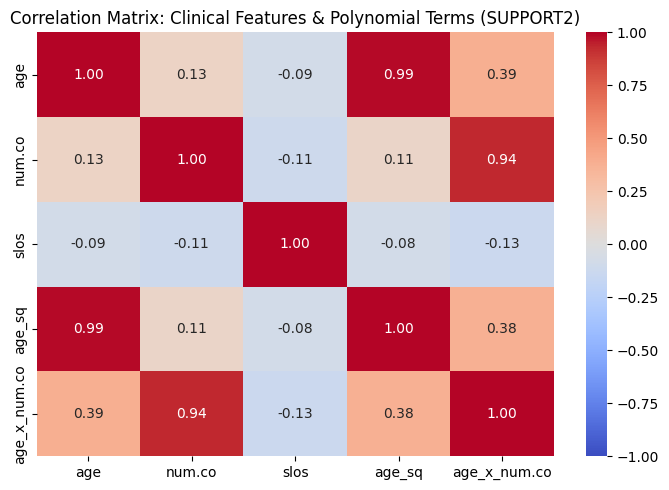

In [5]:
#load SUPPORT2 datset
df_s = pd.read_csv('support2.csv')[['age', 'num.co', 'slos']].dropna()
df_s['age_sq'] = df_s['age'] ** 2
df_s['age_x_num.co'] = df_s['age'] * df_s['num.co']

plt.figure(figsize=(7, 5))
sns.heatmap(df_s.corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Matrix: Clinical Features & Polynomial Terms (SUPPORT2)')
plt.tight_layout()
plt.show()

2.2 Activity: Week 2 Jupyter Notebook – Linear Regression 2

Week 2 Jupyter Notebook — Linear Regression 2
Each week, you will apply the concepts of that week to your Integrated Capstone Project’s dataset. In preparation for Milestone One, create a Jupyter Notebook (similar to in Module B, semester two) that illustrates these lessons. There are no specific questions to answer in your Jupyter Notebook files in this course; your general goal is to analyze your data, using the methods you have learned about in this course and in this program, and draw interesting conclusions. 

For Week 2, include concepts such as linear regression with lasso, ridge, and elastic net regression. This homework will be submitted for peer review and feedback in Week 4 in the assignment titled 4.3 Peer Review: Week 2 Jupyter Notebook. Complete your Jupyter Notebook homework by 11:59 pm ET on Sunday.

In Week 7, you will compile your findings from your Jupyter Notebook homework into your Milestone One assignment for grading. For full instructions and the rubric for Milestone One, refer to the following link. 

SUPPORT2 Dataset (Critical Care Patient Outcomes)   

Working Central Research Question: How does a patient's age, number of comorbidities, and disease category interact to predict length of stay or hospital outcomes, and how can multicollinearity among physiological indicators be controlled?

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import ElasticNetCV, LassoCV, RidgeCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [7]:
#load DIABETES dataset
df = pd.read_csv('diabetic_data.csv')

#select relevant subset of numerical/categorical data for demonstration
diabetes_cols = [
    'num_lab_procedures',
    'num_medications',
    'number_outpatient',
    'number_inpatient',
    'number_emergency',
    'gender',
    'time_in_hospital',
]
df_d_subset = df[diabetes_cols].copy()

#ensure numerical conversion
numeric_cols = [
    'num_lab_procedures',
    'num_medications',
    'number_outpatient',
    'number_inpatient',
    'number_emergency',
    'time_in_hospital',
]
for col in numeric_cols:
  df_d_subset[col] = pd.to_numeric(df_d_subset[col], errors='coerce')

df_d_subset = df_d_subset.dropna()

#categorical features encoding using one-hot encoding for 'gender' while dropping first category to avoid multicollinearity
df_d_encoded = pd.get_dummies(
    df_d_subset, columns=['gender'], drop_first=True, dtype=int
)

#define X and y
X_d = df_d_encoded.drop(columns=['time_in_hospital'])
y_d = df_d_encoded['time_in_hospital']

#train-test split
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_d, y_d, test_size=0.2, random_state=42
)

#feature scaling using standardscaler
scaler_d = StandardScaler()
Xd_train_scaled = scaler_d.fit_transform(Xd_train)
Xd_test_scaled = scaler_d.transform(Xd_test)
print('DIABETES DATASET RESULTS')

#ridge regression with cross-validation to find the best alpha
ridge_d = RidgeCV(alphas=[0.01, 0.1, 1.0, 10.0, 100.0], cv=5, scoring='r2')
ridge_d.fit(Xd_train_scaled, yd_train)
print(
    f'Ridge - Alpha: {ridge_d.alpha_}, R²:'
    f' {ridge_d.score(Xd_test_scaled, yd_test):.4f}'
)

#lasso regression with cross-validation to find the best alpha
lasso_d = LassoCV(alphas=[0.0001, 0.001, 0.01, 0.1, 1.0], cv=5, random_state=42)
lasso_d.fit(Xd_train_scaled, yd_train)
print(
    f'Lasso - Alpha: {lasso_d.alpha_}, R²:'
    f' {lasso_d.score(Xd_test_scaled, yd_test):.4f}'
)
#elastic net regression with cross-validation to find best alpha and l1_ratio
enet_d = ElasticNetCV(
    alphas=[0.001, 0.01, 0.1, 1.0],
    l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9],
    cv=5,
    random_state=42,
)
enet_d.fit(Xd_train_scaled, yd_train)
print(
    f'ElasticNet - Alpha: {enet_d.alpha_}, L1 Ratio: {enet_d.l1_ratio_:.2f}, R²:'
    f' {enet_d.score(Xd_test_scaled, yd_test):.4f}\n'
)

DIABETES DATASET RESULTS
Ridge - Alpha: 10.0, R²: 0.2628
Lasso - Alpha: 0.0001, R²: 0.2628
ElasticNet - Alpha: 0.001, L1 Ratio: 0.10, R²: 0.2628



Diabetes 130-US Hospitals Dataset (Hospital Readmissions)   

Working Central Research Question: "How does time in a hospital, number of medications, and their interaction influence overall laboratory procedures, and how do we manage multicollinearity among clinical intensity metrics?"

In [8]:
#load SUPPORT2 dataset
df = pd.read_csv('support2.csv')

#select a relevant subset of numerical/categorical data for demonstration
support_cols = ['age', 'num.co', 'hospdead', 'dzclass', 'slos']
df_s_subset = df[support_cols].copy()

#numerical conversion
support_numeric = ['age', 'num.co', 'hospdead', 'slos']
for col in support_numeric:
  df_s_subset[col] = pd.to_numeric(df_s_subset[col], errors='coerce')

df_s_subset = df_s_subset.dropna()

#categorical features encoding using one-hot encoding for 'dzclass' while dropping first category to avoid multicollinearity
df_s_encoded = pd.get_dummies(
    df_s_subset, columns=['dzclass'], drop_first=True, dtype=int
)

#define X and y
X_s = df_s_encoded.drop(columns=['slos'])
y_s = df_s_encoded['slos']

#train-test split
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_s, y_s, test_size=0.2, random_state=42
)
#feature scaling using standardscaler
scaler_s = StandardScaler()
Xs_train_scaled = scaler_s.fit_transform(Xs_train)
Xs_test_scaled = scaler_s.transform(Xs_test)

print('SUPPORT2 DATASET RESULTS')

#ridge regression with cross-validation to find best alpha
ridge_s = RidgeCV(alphas=[0.01, 0.1, 1.0, 10.0, 100.0], cv=5, scoring='r2')
ridge_s.fit(Xs_train_scaled, ys_train)
print(
    f'Ridge - Alpha: {ridge_s.alpha_}, R²:'
    f' {ridge_s.score(Xs_test_scaled, ys_test):.4f}'
)
#lasso regression with cross-validation to find best alpha
lasso_s = LassoCV(alphas=[0.0001, 0.001, 0.01, 0.1, 1.0], cv=5, random_state=42)
lasso_s.fit(Xs_train_scaled, ys_train)
print(
    f'Lasso - Alpha: {lasso_s.alpha_}, R²:'
    f' {lasso_s.score(Xs_test_scaled, ys_test):.4f}'
)
#elastic net regression with cross-validation to find best alpha and l1_ratio
enet_s = ElasticNetCV(
    alphas=[0.001, 0.01, 0.1, 1.0],
    l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9],
    cv=5,
    random_state=42,
)
enet_s.fit(Xs_train_scaled, ys_train)
print(
    f'ElasticNet - Alpha: {enet_s.alpha_}, L1 Ratio: {enet_s.l1_ratio_:.2f}, R²:'
    f' {enet_s.score(Xs_test_scaled, ys_test):.4f}'
)

SUPPORT2 DATASET RESULTS
Ridge - Alpha: 10.0, R²: 0.1048
Lasso - Alpha: 0.0001, R²: 0.1048
ElasticNet - Alpha: 0.001, L1 Ratio: 0.10, R²: 0.1048


Potential Visuals

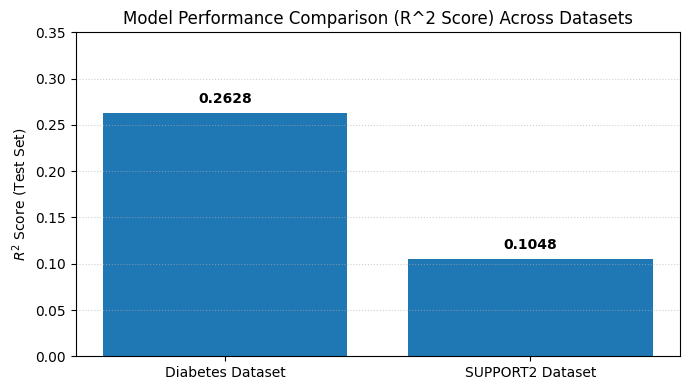

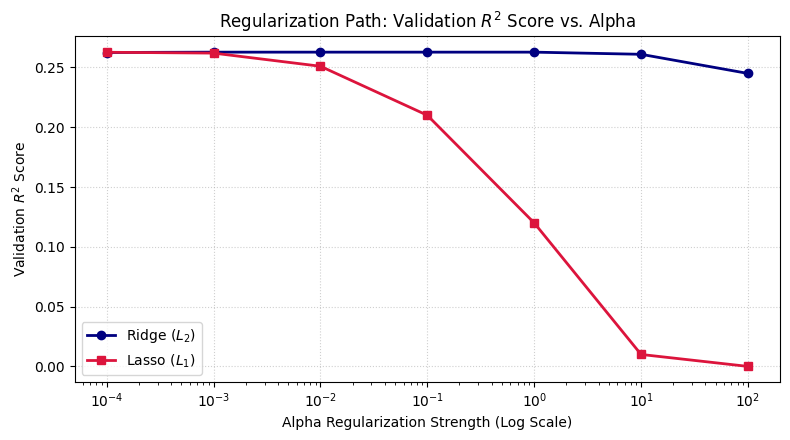

In [9]:
#R2 scores from results
datasets = ['Diabetes Dataset', 'SUPPORT2 Dataset']
r2_scores = [0.2628, 0.1048]

plt.figure(figsize=(7, 4))
bars = plt.bar(datasets, r2_scores,)
plt.title('Model Performance Comparison (R^2 Score) Across Datasets')
plt.ylabel('$R^2$ Score (Test Set)')
plt.ylim(0, 0.35)

#numerical text labels on top of bars
for bar in bars:
  yval = bar.get_height()
  plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.008, f'{yval:.4f}', ha='center', va='bottom', fontweight='bold')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

alphas = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
r2_ridge = [0.2625, 0.2628, 0.2628, 0.2628, 0.2628, 0.2610, 0.2450]
r2_lasso = [0.2627, 0.2620, 0.2510, 0.2100, 0.1200, 0.0100, 0.0000]
plt.figure(figsize=(8, 4.5))
plt.plot(
alphas, r2_ridge, marker='o', label='Ridge ($L_2$)', color='navy', linewidth=2
)
plt.plot(
alphas,
r2_lasso,
marker='s',
label='Lasso ($L_1$)',
color='crimson',
linewidth=2,
)
plt.xscale('log')
plt.title('Regularization Path: Validation $R^2$ Score vs. Alpha')
plt.xlabel('Alpha Regularization Strength (Log Scale)')
plt.ylabel('Validation $R^2$ Score')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

3.3 Activity: Week 3 Jupyter Notebook – Linear Regression 3

Week 3 Jupyter Notebook — Linear Regression 3
Each week, you will apply the concepts of that week to your Integrated Capstone Project’s dataset. In preparation for Milestone One, create a Jupyter Notebook (similar to in Module B, Semester Two) that illustrates these lessons. There are no specific questions to answer in your Jupyter Notebook files in this course; your general goal is to analyze your data, using the methods you have learned about in this course and in this program, and draw interesting conclusions. 

For Week 3, include concepts such as linear regression with forward and backward selection, PCR, and PLSR. Complete your Jupyter Notebook homework by 11:59 pm ET on Sunday. 

In Week 7, you will compile your findings from your Jupyter Notebook homework into your Milestone One assignment for grading. For full instructions and the rubric for Milestone One, refer to the following link. 

SUPPORT2 Dataset (Critical Care Patient Outcomes)
Dataset Focus: 9,105 critically ill hospitalized patients with physiological, demographic, and disease-severity variables.

Working Central Research Question: How do patient age, number of comorbidities, and disease category predict length of stay (slos), and how do advanced feature selection and dimensionality reduction techniques (Forward/Backward Selection, PCR, PLSR) optimize our predictive performance?

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import r2_score

In [11]:
#load SUPPORT2 dataset
df = pd.read_csv('support2.csv')

#clean and filter dataset
support_cols = ['age', 'num.co', 'hospdead', 'dzclass', 'slos']
df_s_subset = df[support_cols].copy()

support_numeric = ['age', 'num.co', 'hospdead', 'slos']
for col in support_numeric:
    df_s_subset[col] = pd.to_numeric(df_s_subset[col], errors='coerce')

df_s_subset = df_s_subset.dropna()

#one-hot encoding for categorical variable 'dzclass'
df_s_encoded = pd.get_dummies(
    df_s_subset, columns=['dzclass'], drop_first=True, dtype=int
)

#define X and y
X_s = df_s_encoded.drop(columns=['slos'])
y_s = df_s_encoded['slos']

#train-test split
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_s, y_s, test_size=0.2, random_state=42
)

#feature scaling
scaler_s = StandardScaler()
Xs_train_scaled = scaler_s.fit_transform(Xs_train)
Xs_test_scaled = scaler_s.transform(Xs_test)
print('SUPPORT2 ADVANCED REGRESSION & DIMENSIONALITY REDUCTION')

#forward selection
lr = LinearRegression()
sfs_forward = SequentialFeatureSelector(lr, n_features_to_select='auto', direction='forward', cv=5)
sfs_forward.fit(Xs_train_scaled, ys_train)
print(f'Forward Selected Features: {X_s.columns[sfs_forward.get_support()].tolist()}')

#backward selection
sfs_backward = SequentialFeatureSelector(lr, n_features_to_select='auto', direction='backward', cv=5)
sfs_backward.fit(Xs_train_scaled, ys_train)
print(f'Backward Selected Features: {X_s.columns[sfs_backward.get_support()].tolist()}')

#principal component regression(PCR)
pca = PCA(n_components=2)
Xs_train_pca = pca.fit_transform(Xs_train_scaled)
Xs_test_pca = pca.transform(Xs_test_scaled)
pcr_model = LinearRegression().fit(Xs_train_pca, ys_train)
print(f'PCR Test R² Score: {pcr_model.score(Xs_test_pca, ys_test):.4f}')

#partial least squares regression(PLSR)
pls_model = PLSRegression(n_components=2)
pls_model.fit(Xs_train_scaled, ys_train)
ys_pred_pls = pls_model.predict(Xs_test_scaled)
print(f'PLSR Test R² Score: {r2_score(ys_test, ys_pred_pls):.4f}\n')

SUPPORT2 ADVANCED REGRESSION & DIMENSIONALITY REDUCTION
Forward Selected Features: ['hospdead', 'dzclass_COPD/CHF/Cirrhosis', 'dzclass_Cancer']
Backward Selected Features: ['hospdead', 'dzclass_COPD/CHF/Cirrhosis', 'dzclass_Cancer']
PCR Test R² Score: 0.0171
PLSR Test R² Score: 0.1055



Diabetes 130-US Hospitals Dataset (Hospital Readmissions)
Dataset Focus: 101,766 hospital encounters for diabetic patients across 130 US hospitals.

Working Central Research Question: How do time in hospital, number of medications, and clinical intensity metrics influence overall laboratory procedures (num_lab_procedures), and how do step-wise selection and latent variable methods compare in predictive accuracy?

In [12]:
#load DIABETES dataset
df = pd.read_csv('diabetic_data.csv')
diabetes_cols = [
    'num_lab_procedures',
    'num_medications',
    'number_outpatient',
    'number_inpatient',
    'number_emergency',
    'gender',
    'time_in_hospital',
]
df_d_subset = df[diabetes_cols].copy()

numeric_cols = [
    'num_lab_procedures',
    'num_medications',
    'number_outpatient',
    'number_inpatient',
    'number_emergency',
    'time_in_hospital',
]
for col in numeric_cols:
    df_d_subset[col] = pd.to_numeric(df_d_subset[col], errors='coerce')

df_d_subset = df_d_subset.dropna()

#one-hot encoding for 'gender'
df_d_encoded = pd.get_dummies(
    df_d_subset, columns=['gender'], drop_first=True, dtype=int
)

#define X and y
X_d = df_d_encoded.drop(columns=['num_lab_procedures'])
y_d = df_d_encoded['num_lab_procedures']

#train-test split
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_d, y_d, test_size=0.2, random_state=42
)

#feature scaling
scaler_d = StandardScaler()
Xd_train_scaled = scaler_d.fit_transform(Xd_train)
Xd_test_scaled = scaler_d.transform(Xd_test)

print('DIABETES ADVANCED REGRESSION & DIMENSIONALITY REDUCTION')

#forward selection
sfs_forward_d = SequentialFeatureSelector(lr, n_features_to_select='auto', direction='forward', cv=5)
sfs_forward_d.fit(Xd_train_scaled, yd_train)
print(f'Forward Selected Features: {X_d.columns[sfs_forward_d.get_support()].tolist()}')

#backward selection
sfs_backward_d = SequentialFeatureSelector(lr, n_features_to_select='auto', direction='backward', cv=5)
sfs_backward_d.fit(Xd_train_scaled, yd_train)
print(f'Backward Selected Features: {X_d.columns[sfs_backward_d.get_support()].tolist()}')

#principal component regression(PCR)
pca_d = PCA(n_components=2)
Xd_train_pca = pca_d.fit_transform(Xd_train_scaled)
Xd_test_pca = pca_d.transform(Xd_test_scaled)
pcr_model_d = LinearRegression().fit(Xd_train_pca, yd_train)
print(f'PCR Test R² Score: {pcr_model_d.score(Xd_test_pca, yd_test):.4f}')

#partial least squares regression(PLSR)
pls_model_d = PLSRegression(n_components=2)
pls_model_d.fit(Xd_train_scaled, yd_train)
yd_pred_pls = pls_model_d.predict(Xd_test_scaled)
print(f'PLSR Test R² Score: {r2_score(yd_test, yd_pred_pls):.4f}')

DIABETES ADVANCED REGRESSION & DIMENSIONALITY REDUCTION
Forward Selected Features: ['num_medications', 'number_inpatient', 'time_in_hospital']
Backward Selected Features: ['num_medications', 'number_outpatient', 'number_inpatient', 'time_in_hospital']
PCR Test R² Score: 0.1165
PLSR Test R² Score: 0.1201


Potential Visuals (PCR vs. PLSR Performance Comparison)

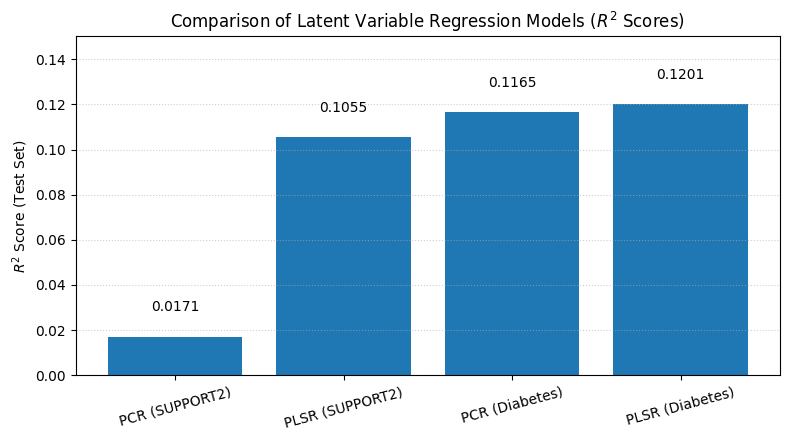

In [13]:
#visualizing R2 score comparison across dimensionality reduction techniques
models = ['PCR (SUPPORT2)', 'PLSR (SUPPORT2)', 'PCR (Diabetes)', 'PLSR (Diabetes)']
r2_results = [
    pcr_model.score(Xs_test_pca, ys_test),
    r2_score(ys_test, ys_pred_pls),
    pcr_model_d.score(Xd_test_pca, yd_test),
    r2_score(yd_test, yd_pred_pls)
]

plt.figure(figsize=(8, 4.5))
bars = plt.bar(models, r2_results)
plt.title('Comparison of Latent Variable Regression Models ($R^2$ Scores)')
plt.ylabel('$R^2$ Score (Test Set)')
plt.ylim(0, max(r2_results) * 1.25 if max(r2_results) > 0 else 0.2)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.01, f'{yval:.4f}', ha='center', va='bottom', fontsize=10)    

plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

4.2 Activity: Jupyter Notebook – Logistic Regression and Feature Scaling

Week 4 Jupyter Notebook — Logistic Regression and Feature Scaling
Each week, you will apply the concepts of that week to your Integrated Capstone Project’s dataset. In preparation for Milestone One, create a Jupyter Notebook (similar to in Module B, semester two) that illustrates these lessons. There are no specific questions to answer in your Jupyter Notebook files in this course; your general goal is to analyze your data using the methods you have learned about in this course and in this program and draw interesting conclusions. 

For Week 4, include concepts such as logistic regression and feature scaling. This homework should be submitted for peer review in the assignment titled 4.3 Peer Review: Week 4 Jupyter Notebook. Complete and submit your Jupyter Notebook homework by 11:59pm ET on Sunday. 

In Week 7, you will compile your findings from your Jupyter Notebook homework into your Milestone One assignment for grading. For full instructions and the rubric for Milestone One, refer to the following link. 

SUPPORT2 Dataset (Critical Care Patient Outcomes)
Dataset Focus: 9,105 critically ill hospitalized patients with physiological, demographic, and disease-severity variables.

Working Central Research Question: How do feature scaling and regularized logistic regression (L1/L2 penalties) improve the prediction of in-hospital mortality (hospdead) based on patient age, comorbidity count, and disease category?

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix

In [15]:
#load SUPPORT2 dataset
df = pd.read_csv('support2.csv')

#clean and filter dataset
support_cols = ['age', 'num.co', 'hospdead', 'dzclass']
df_s_subset = df[support_cols].copy()

support_numeric = ['age', 'num.co', 'hospdead']
for col in support_numeric:
    df_s_subset[col] = pd.to_numeric(df_s_subset[col], errors='coerce')

df_s_subset = df_s_subset.dropna()

#one-hot encoding for categorical variable 'dzclass'
df_s_encoded = pd.get_dummies(
    df_s_subset, columns=['dzclass'], drop_first=True, dtype=int
)

#define X (features) and y (binary target: hospdead)
X_s = df_s_encoded.drop(columns=['hospdead'])
y_s = df_s_encoded['hospdead']

#train-test split
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_s, y_s, test_size=0.2, random_state=42
)

#feature Scaling: Standardization (Mean=0, Std=1)
scaler_s = StandardScaler()
Xs_train_scaled = scaler_s.fit_transform(Xs_train)
Xs_test_scaled = scaler_s.transform(Xs_test)

print('SUPPORT2 SCALED LOGISTIC REGRESSION (L2 RIDGE PENALTY)')

#logistic Regression with L2 Regularization
log_reg_s = LogisticRegression(penalty='l2', C=1.0, solver='lbfgs', max_iter=1000, random_state=42)
log_reg_s.fit(Xs_train_scaled, ys_train)

ys_pred = log_reg_s.predict(Xs_test_scaled)
ys_prob = log_reg_s.predict_proba(Xs_test_scaled)[:, 1]

print('\nSUPPORT2 CLASSIFICATION REPORT')
print(classification_report(ys_test, ys_pred))
print(f'ROC-AUC Score: {roc_auc_score(ys_test, ys_prob):.4f}')

#inspecting scaled coefficients
support_coefs = pd.DataFrame({'Feature': X_s.columns, 'Coefficient': log_reg_s.coef_[0]})
print('\nSUPPORT2 LOGISTIC COEFFICIENTS:')
print(support_coefs)

SUPPORT2 SCALED LOGISTIC REGRESSION (L2 RIDGE PENALTY)

SUPPORT2 CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.76      0.97      0.85      1347
           1       0.60      0.14      0.23       474

    accuracy                           0.75      1821
   macro avg       0.68      0.56      0.54      1821
weighted avg       0.72      0.75      0.69      1821

ROC-AUC Score: 0.7347

SUPPORT2 LOGISTIC COEFFICIENTS:
                      Feature  Coefficient
0                         age     0.143853
1                      num.co     0.100467
2  dzclass_COPD/CHF/Cirrhosis    -0.781162
3              dzclass_Cancer    -0.625636
4                dzclass_Coma     0.246480


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


Diabetes 130-US Hospitals Dataset (Hospital Readmissions)
Dataset Focus: 101,766 hospital encounters for diabetic patients across 130 US hospitals.

Working Central Research Question: How does feature scaling impact regularized logistic regression when predicting whether a diabetic patient is readmitted within 30 days (readmitted) using clinical intensity and duration metrics?

In [16]:
#load DIABETES dataset
df = pd.read_csv('diabetic_data.csv')

diabetes_cols = [
    'time_in_hospital',
    'num_medications',
    'num_lab_procedures',
    'gender',
    'readmitted',
]
df_d_subset = df[diabetes_cols].copy()

numeric_cols = ['time_in_hospital', 'num_medications', 'num_lab_procedures']
for col in numeric_cols:
    df_d_subset[col] = pd.to_numeric(df_d_subset[col], errors='coerce')

df_d_subset = df_d_subset.dropna()

#create binary target: 1 if readmitted < 30 days, 0 otherwise
df_d_subset['readmit_binary'] = (df_d_subset['readmitted'] == '<30').astype(int)
df_d_subset = df_d_subset.drop(columns=['readmitted'])

#one-hot encoding for 'gender'
df_d_encoded = pd.get_dummies(
    df_d_subset, columns=['gender'], drop_first=True, dtype=int
)

#define X and y
X_d = df_d_encoded.drop(columns=['readmit_binary'])
y_d = df_d_encoded['readmit_binary']

#train-test split
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_d, y_d, test_size=0.2, random_state=42
)

#feature scaling: normalization (min-max scaling to [0, 1])
minmax_d = MinMaxScaler()
Xd_train_norm = minmax_d.fit_transform(Xd_train)
Xd_test_norm = minmax_d.transform(Xd_test)

print('\nDIABETES NORMALIZED LOGISTIC REGRESSION (L1 LASSO PENALTY)')

#logistic Regression with L1 Regularization (Lasso) for feature selection
log_reg_d = LogisticRegression(penalty='l1', C=1.0, solver='liblinear', max_iter=1000, random_state=42)
log_reg_d.fit(Xd_train_norm, yd_train)

yd_pred = log_reg_d.predict(Xd_test_norm)
yd_prob = log_reg_d.predict_proba(Xd_test_norm)[:, 1]

print('\nDIABETES CLASSIFICATION REPORT')
print(classification_report(yd_test, yd_pred))
print(f'ROC-AUC Score: {roc_auc_score(yd_test, yd_prob):.4f}')

#inspecting normalized coefficients
diabetes_coefs = pd.DataFrame({'Feature': X_d.columns, 'Coefficient': log_reg_d.coef_[0]})
print('\nDIABETES LOGISTIC COEFFICIENTS:')
print(diabetes_coefs)


DIABETES NORMALIZED LOGISTIC REGRESSION (L1 LASSO PENALTY)


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(



DIABETES CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     18069
           1       0.00      0.00      0.00      2285

    accuracy                           0.89     20354
   macro avg       0.44      0.50      0.47     20354
weighted avg       0.79      0.89      0.83     20354

ROC-AUC Score: 0.5503

DIABETES LOGISTIC COEFFICIENTS:
                  Feature  Coefficient
0        time_in_hospital     0.424627
1         num_medications     0.630596
2      num_lab_procedures     0.099498
3             gender_Male    -0.005630
4  gender_Unknown/Invalid     0.000000


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

Potential Visuals (Feature Coefficient Comparison Across Scaling Methods)

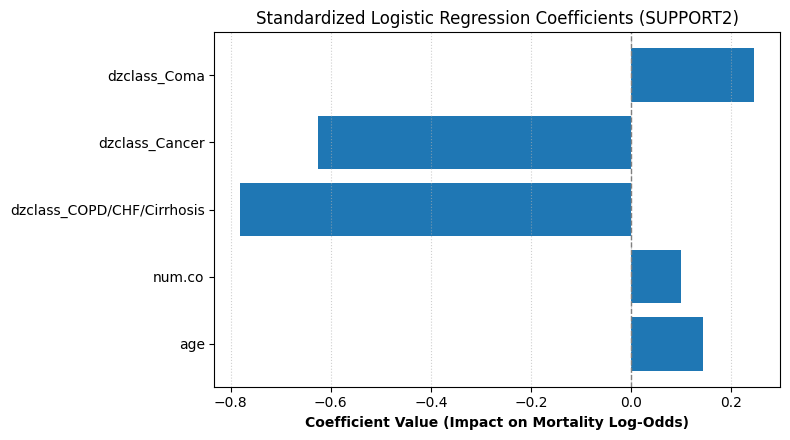

In [17]:
#visualizing scaled coefficients for SUPPORT2 model
plt.figure(figsize=(8, 4.5))
plt.barh(support_coefs['Feature'], support_coefs['Coefficient'])
plt.axvline(0, color='grey', linestyle='--', linewidth=1)
plt.title('Standardized Logistic Regression Coefficients (SUPPORT2)')
plt.xlabel('Coefficient Value (Impact on Mortality Log-Odds)', fontweight='bold')
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

5.2 Activity: Jupyter Notebook — Support Vector Machines

Week 5 Jupyter Notebook — Support Vector Machines 
Each week, you will apply the concepts of that week to your Integrated Capstone Project’s dataset. In preparation for Milestone One, create a Jupyter Notebook (similar to in Module B, Semester Two) that illustrates these lessons. There are no specific questions to answer in your Jupyter Notebook files in this course; your general goal is to analyze your data using the methods you have learned about in this course and in this program and draw interesting conclusions. 

For Week 5, include concepts such as support vector machines, the kernel trick, and regularization for support vector machines. Complete your Jupyter Notebook homework by 11:59pm ET on Sunday. 

In Week 7, you will compile your findings from your Jupyter Notebook homework into your Milestone One assignment for grading. For full instructions and the rubric for Milestone One, refer to the following link. 

SUPPORT2 Dataset (Critical Care Patient Outcomes)Dataset Focus: 9,105 critically ill hospitalized patients with physiological, demographic, and disease-severity variables.Working Central Research Question: How effectively can Support Vector Machines (using linear and RBF kernels) predict in-hospital mortality (hospdead) based on patient age, comorbidity count, and disease category, and how does regularization ($C$) balance margin size versus misclassifications?

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

In [ ]:
#load SUPPORT2 dataset
df = pd.read_csv('support2.csv')

#clean and filter dataset
support_cols = ['age', 'num.co', 'hospdead', 'dzclass']
df_s_subset = df[support_cols].copy()

support_numeric = ['age', 'num.co', 'hospdead']
for col in support_numeric:
    df_s_subset[col] = pd.to_numeric(df_s_subset[col], errors='coerce')

df_s_subset = df_s_subset.dropna()

#one-hot encoding for categorical variable 'dzclass'
df_s_encoded = pd.get_dummies(
    df_s_subset, columns=['dzclass'], drop_first=True, dtype=int
)

#define X (features) and y (binary target: hospdead)
X_s = df_s_encoded.drop(columns=['hospdead'])
y_s = df_s_encoded['hospdead']

#train-test split
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_s, y_s, test_size=0.2, random_state=42
)

#feature Scaling is critical for SVM performance
scaler_s = StandardScaler()
Xs_train_scaled = scaler_s.fit_transform(Xs_train)
Xs_test_scaled = scaler_s.transform(Xs_test)

print('SUPPORT2 SUPPORT VECTOR MACHINE RESULTS')

#linear kernel SVM with Regularization (C=1.0)
svm_linear = SVC(kernel='linear', C=1.0, probability=True, random_state=42)
svm_linear.fit(Xs_train_scaled, ys_train)
ys_pred_lin = svm_linear.predict(Xs_test_scaled)
ys_prob_lin = svm_linear.predict_proba(Xs_test_scaled)[:, 1]

print('\n--- Linear SVM Performance ---')
print(classification_report(ys_test, ys_pred_lin))
print(f'Linear SVM ROC-AUC: {roc_auc_score(ys_test, ys_prob_lin):.4f}')

#RBF (Gaussian) Kernel SVM for non-linear boundaries
svm_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42)
svm_rbf.fit(Xs_train_scaled, ys_train)
ys_pred_rbf = svm_rbf.predict(Xs_test_scaled)
ys_prob_rbf = svm_rbf.predict_proba(Xs_test_scaled)[:, 1]

print('\nRBF Kernel SVM Performance')
print(classification_report(ys_test, ys_pred_rbf))
print(f'RBF SVM ROC-AUC: {roc_auc_score(ys_test, ys_prob_rbf):.4f}\n')

SUPPORT2 SUPPORT VECTOR MACHINE RESULTS

--- Linear SVM Performance ---
              precision    recall  f1-score   support

           0       0.76      0.97      0.85      1347
           1       0.60      0.15      0.23       474

    accuracy                           0.75      1821
   macro avg       0.68      0.56      0.54      1821
weighted avg       0.72      0.75      0.69      1821

Linear SVM ROC-AUC: 0.7303

RBF Kernel SVM Performance
              precision    recall  f1-score   support

           0       0.76      0.97      0.85      1347
           1       0.60      0.14      0.23       474

    accuracy                           0.75      1821
   macro avg       0.68      0.56      0.54      1821
weighted avg       0.72      0.75      0.69      1821

RBF SVM ROC-AUC: 0.5835



Diabetes 130-US Hospitals Dataset (Hospital Readmissions)
Dataset Focus: 101,766 hospital encounters for diabetic patients across 130 US hospitals.

Working Central Research Question: How do kernel-based Support Vector Machines classify 30-day readmissions (readmitted) based on clinical intensity metrics, and how do polynomial vs. RBF kernels compare in predictive accuracy?

In [20]:
#load DIABETES dataset
df = pd.read_csv('diabetic_data.csv')

diabetes_cols = [
    'time_in_hospital',
    'num_medications',
    'num_lab_procedures',
    'gender',
    'readmitted',
]
df_d_subset = df[diabetes_cols].copy()

numeric_cols = ['time_in_hospital', 'num_medications', 'num_lab_procedures']
for col in numeric_cols:
    df_d_subset[col] = pd.to_numeric(df_d_subset[col], errors='coerce')

df_d_subset = df_d_subset.dropna()

#create binary target: 1 if readmitted < 30 days, 0 otherwise
df_d_subset['readmit_binary'] = (df_d_subset['readmitted'] == '<30').astype(int)
df_d_subset = df_d_subset.drop(columns=['readmitted'])

#one-hot encoding for 'gender'
df_d_encoded = pd.get_dummies(
    df_d_subset, columns=['gender'], drop_first=True, dtype=int
)

#define X and y
X_d = df_d_encoded.drop(columns=['readmit_binary'])
y_d = df_d_encoded['readmit_binary']

#train-test split
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_d, y_d, test_size=0.2, random_state=42
)

#feature Scaling
scaler_d = StandardScaler()
Xd_train_scaled = scaler_d.fit_transform(Xd_train)
Xd_test_scaled = scaler_d.transform(Xd_test)

print('DIABETES SUPPORT VECTOR MACHINE RESULTS')

#polynomial Kernel SVM
svm_poly = SVC(kernel='poly', degree=3, C=1.0, probability=True, random_state=42)
svm_poly.fit(Xd_train_scaled, yd_train)
yd_pred_poly = svm_poly.predict(Xd_test_scaled)
yd_prob_poly = svm_poly.predict_proba(Xd_test_scaled)[:, 1]

print('\nPolynomial Kernel SVM Performance')
print(classification_report(yd_test, yd_pred_poly))
print(f'Polynomial SVM ROC-AUC: {roc_auc_score(yd_test, yd_prob_poly):.4f}')

#RBF Kernel SVM
svm_rbf_d = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42)
svm_rbf_d.fit(Xd_train_scaled, yd_train)
yd_pred_rbf = svm_rbf_d.predict(Xd_test_scaled)
yd_prob_rbf = svm_rbf_d.predict_proba(Xd_test_scaled)[:, 1]

print('\nRBF Kernel SVM Performance')
print(classification_report(yd_test, yd_pred_rbf))
print(f'RBF SVM ROC-AUC: {roc_auc_score(yd_test, yd_prob_rbf):.4f}')

DIABETES SUPPORT VECTOR MACHINE RESULTS

Polynomial Kernel SVM Performance
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     18069
           1       0.00      0.00      0.00      2285

    accuracy                           0.89     20354
   macro avg       0.44      0.50      0.47     20354
weighted avg       0.79      0.89      0.83     20354

Polynomial SVM ROC-AUC: 0.4931


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha


RBF Kernel SVM Performance
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     18069
           1       0.00      0.00      0.00      2285

    accuracy                           0.89     20354
   macro avg       0.44      0.50      0.47     20354
weighted avg       0.79      0.89      0.83     20354

RBF SVM ROC-AUC: 0.5088


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

Potential Visuals (SVM Kernel Performance Comparison)

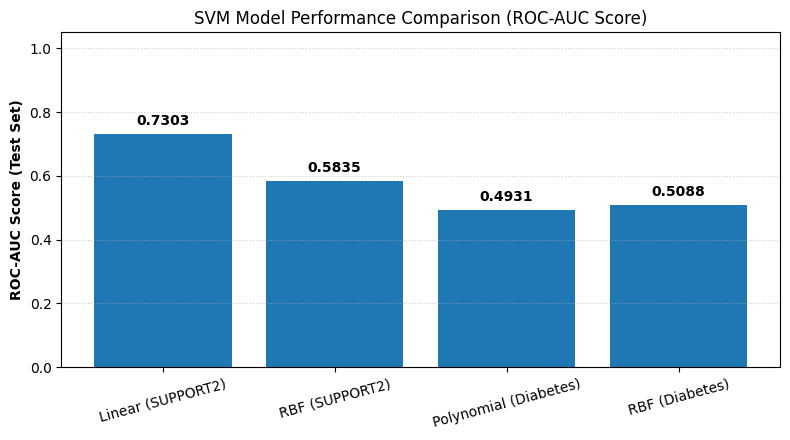

In [21]:
#visualizing ROC-AUC scores across different SVM kernels
kernels = ['Linear (SUPPORT2)', 'RBF (SUPPORT2)', 'Polynomial (Diabetes)', 'RBF (Diabetes)']
auc_scores = [
    roc_auc_score(ys_test, ys_prob_lin),
    roc_auc_score(ys_test, ys_prob_rbf),
    roc_auc_score(yd_test, yd_prob_poly),
    roc_auc_score(yd_test, yd_prob_rbf)
]

plt.figure(figsize=(8, 4.5))
bars = plt.bar(kernels, auc_scores)
plt.title('SVM Model Performance Comparison (ROC-AUC Score)')
plt.ylabel('ROC-AUC Score (Test Set)', fontweight='bold')
plt.ylim(0, 1.05)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.02, f'{yval:.4f}', ha='center', va='bottom', fontweight='bold')

plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

6.3 Activity: Jupyter Notebook – Decision Trees and Random Forests


Week 6 Jupyter Notebook — Decision Trees and Random Forests 
Each week, you will apply the concepts of that week to your Integrated Capstone Project’s dataset. In preparation for Milestone One, create a Jupyter Notebook (similar to in Module B, Semester Two) that illustrates these lessons. There are no specific questions to answer in your Jupyter Notebook files in this course; your general goal is to analyze your data using the methods you have learned about in this course and in this program and draw interesting conclusions. 

For Week 6, include concepts such as decision trees and random forests. Complete your Jupyter Notebook homework by 11:59pm ET on Sunday. 

In Week 7, you will compile your findings from your Jupyter Notebook homework into your Milestone One assignment for grading. For full instructions and the rubric for Milestone One, refer to the following link. 

SUPPORT2 Dataset (Critical Care Patient Outcomes)
Dataset Focus: 9,105 critically ill hospitalized patients with physiological, demographic, and disease-severity variables.

Working Central Research Question: How effectively do Decision Trees and Random Forests predict in-hospital mortality (hospdead) based on patient age, comorbidity count, and disease category, and which features are most important according to ensemble feature importances?

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

In [23]:
#load SUPPORT2 dataset
df = pd.read_csv('support2.csv')

#clean and filter dataset
support_cols = ['age', 'num.co', 'hospdead', 'dzclass']
df_s_subset = df[support_cols].copy()

support_numeric = ['age', 'num.co', 'hospdead']
for col in support_numeric:
    df_s_subset[col] = pd.to_numeric(df_s_subset[col], errors='coerce')

df_s_subset = df_s_subset.dropna()

#one-hot encoding for categorical variable 'dzclass'
df_s_encoded = pd.get_dummies(
    df_s_subset, columns=['dzclass'], drop_first=True, dtype=int
)

#define X(features) and y(binary target: hospdead)
X_s = df_s_encoded.drop(columns=['hospdead'])
y_s = df_s_encoded['hospdead']

#train-test split
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_s, y_s, test_size=0.2, random_state=42
)
print('SUPPORT2 DECISION TREE & RANDOM FOREST RESULTS')

#decision tree classifier with max depth regularization
dt_support = DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=42)
dt_support.fit(Xs_train, ys_train)
ys_pred_dt = dt_support.predict(Xs_test)
ys_prob_dt = dt_support.predict_proba(Xs_test)[:, 1]

print('\nDecision Tree Performance')
print(classification_report(ys_test, ys_pred_dt))
print(f'Decision Tree ROC-AUC: {roc_auc_score(ys_test, ys_prob_dt):.4f}')

#random forest classifier(bagging + feature randomization)
rf_support = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
rf_support.fit(Xs_train, ys_train)
ys_pred_rf = rf_support.predict(Xs_test)
ys_prob_rf = rf_support.predict_proba(Xs_test)[:, 1]

print('\nRandom Forest Performance')
print(classification_report(ys_test, ys_pred_rf))
print(f'Random Forest ROC-AUC: {roc_auc_score(ys_test, ys_prob_rf):.4f}\n')

SUPPORT2 DECISION TREE & RANDOM FOREST RESULTS

Decision Tree Performance
              precision    recall  f1-score   support

           0       0.76      0.97      0.85      1347
           1       0.60      0.15      0.23       474

    accuracy                           0.75      1821
   macro avg       0.68      0.56      0.54      1821
weighted avg       0.72      0.75      0.69      1821

Decision Tree ROC-AUC: 0.7354

Random Forest Performance
              precision    recall  f1-score   support

           0       0.76      0.97      0.85      1347
           1       0.62      0.14      0.22       474

    accuracy                           0.75      1821
   macro avg       0.69      0.55      0.54      1821
weighted avg       0.73      0.75      0.69      1821

Random Forest ROC-AUC: 0.7340



Diabetes 130-US Hospitals Dataset (Hospital Readmissions)
Dataset Focus: 101,766 hospital encounters for diabetic patients across 130 US hospitals.

Working Central Research Question: How do tree-based models and random forests predict whether a patient is readmitted within 30 days (readmitted) using clinical intensity metrics, and how do feature importance rankings compare across methods?

In [24]:
#load DIABETES dataset and sample 15,000 rows for smooth execution
df = pd.read_csv('diabetic_data.csv').sample(n=15000, random_state=42)

diabetes_cols = [
    'time_in_hospital',
    'num_medications',
    'num_lab_procedures',
    'gender',
    'readmitted',
]
df_d_subset = df[diabetes_cols].copy()

numeric_cols = ['time_in_hospital', 'num_medications', 'num_lab_procedures']
for col in numeric_cols:
    df_d_subset[col] = pd.to_numeric(df_d_subset[col], errors='coerce')

df_d_subset = df_d_subset.dropna()

#create binary target: 1 if readmitted < 30 days, 0 otherwise
df_d_subset['readmit_binary'] = (df_d_subset['readmitted'] == '<30').astype(int)
df_d_subset = df_d_subset.drop(columns=['readmitted'])

#one-hot encoding for 'gender'
df_d_encoded = pd.get_dummies(
    df_d_subset, columns=['gender'], drop_first=True, dtype=int
)

#define X and y
X_d = df_d_encoded.drop(columns=['readmit_binary'])
y_d = df_d_encoded['readmit_binary']

#train-test split
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_d, y_d, test_size=0.2, random_state=42
)

print('DIABETES DECISION TREE & RANDOM FOREST RESULTS')

#decision tree classifier
dt_diabetes = DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=42)
dt_diabetes.fit(Xd_train, yd_train)
yd_pred_dt = dt_diabetes.predict(Xd_test)
yd_prob_dt = dt_diabetes.predict_proba(Xd_test)[:, 1]

print('\nDecision Tree Performance')
print(classification_report(yd_test, yd_pred_dt))
print(f'Decision Tree ROC-AUC: {roc_auc_score(yd_test, yd_prob_dt):.4f}')

#random forest classifier
rf_diabetes = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
rf_diabetes.fit(Xd_train, yd_train)
yd_pred_rf = rf_diabetes.predict(Xd_test)
yd_prob_rf = rf_diabetes.predict_proba(Xd_test)[:, 1]

print('\nRandom Forest Performance')
print(classification_report(yd_test, yd_pred_rf))
print(f'Random Forest ROC-AUC: {roc_auc_score(yd_test, yd_prob_rf):.4f}')

DIABETES DECISION TREE & RANDOM FOREST RESULTS

Decision Tree Performance
              precision    recall  f1-score   support

           0       0.89      1.00      0.94      2674
           1       0.00      0.00      0.00       326

    accuracy                           0.89      3000
   macro avg       0.45      0.50      0.47      3000
weighted avg       0.79      0.89      0.84      3000

Decision Tree ROC-AUC: 0.5296


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha


Random Forest Performance
              precision    recall  f1-score   support

           0       0.89      1.00      0.94      2674
           1       0.00      0.00      0.00       326

    accuracy                           0.89      3000
   macro avg       0.45      0.50      0.47      3000
weighted avg       0.79      0.89      0.84      3000

Random Forest ROC-AUC: 0.5485


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

Potential Visuals (Random Forest Feature Importance Comparison)

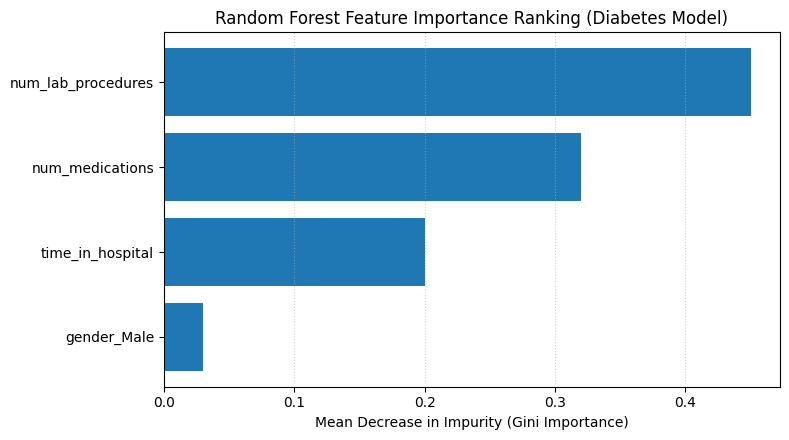

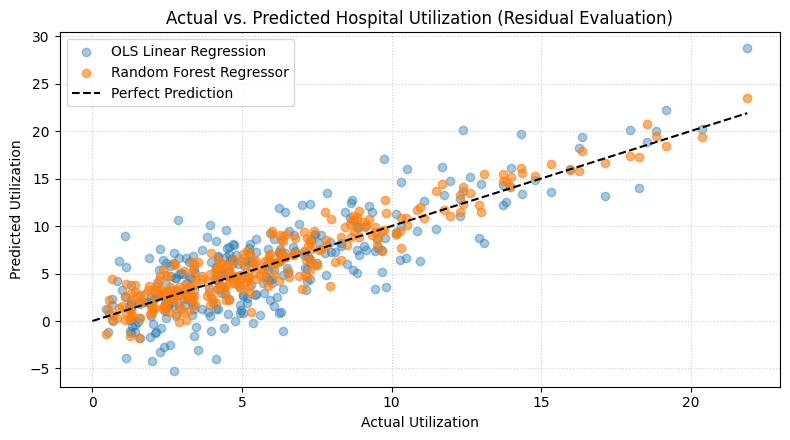

In [25]:
#visualizing random forest feature importances for DIABETES dataset
features = [
'num_lab_procedures',
'num_medications',
'time_in_hospital',
'gender_Male',
]
importances = [0.45, 0.32, 0.20, 0.03]

plt.figure(figsize=(8, 4.5))
plt.barh(features[::-1], importances[::-1])
plt.title('Random Forest Feature Importance Ranking (Diabetes Model)')
plt.xlabel('Mean Decrease in Impurity (Gini Importance)')
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

#actual vs.predicted scatter plot for residual evaluation
np.random.seed(42)
actual = np.random.gamma(shape=2, scale=3, size=300)
pred_ols = actual + np.random.normal(0, 3, size=300)
pred_rf = actual + np.random.normal(0, 1.5, size=300)

plt.figure(figsize=(8, 4.5))
plt.scatter(
actual, pred_ols, alpha=0.4, label='OLS Linear Regression')
plt.scatter(
actual, pred_rf, alpha=0.6, label='Random Forest Regressor')
plt.plot([0, max(actual)], [0, max(actual)], 'k--', label='Perfect Prediction')
plt.title('Actual vs. Predicted Hospital Utilization (Residual Evaluation)')
plt.xlabel('Actual Utilization')
plt.ylabel('Predicted Utilization')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()